In [3]:
import duckdb
import numpy as np
import matplotlib.pyplot as plt

RAW_GLOB = '../data/raw/**/*.parquet'
EMB_COLS = [f'A{i:02d}' for i in range(64)]
TARGET_CLASS = 'Tree cover'
MAX_POINTS = 20000

emb_sel = ", ".join(EMB_COLS)
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
df = con.execute(f"""
    SELECT {emb_sel}
    FROM read_parquet('{RAW_GLOB}')
    WHERE label_name = '{TARGET_CLASS}'
    USING SAMPLE {MAX_POINTS} ROWS
""").df()
con.close()

X = df[EMB_COLS].to_numpy(dtype='float64')
print(f"{TARGET_CLASS}: {X.shape[0]} points, {X.shape[1]} dims")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tree cover: 7075 points, 64 dims


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Xs = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.90, random_state=42)
Xr = pca.fit_transform(Xs)
print(f"reduced to {Xr.shape[1]} dims (90% variance)")
print("cumulative explained variance:", pca.explained_variance_ratio_.cumsum()[-1].round(3))

reduced to 21 dims (90% variance)
cumulative explained variance: 0.905


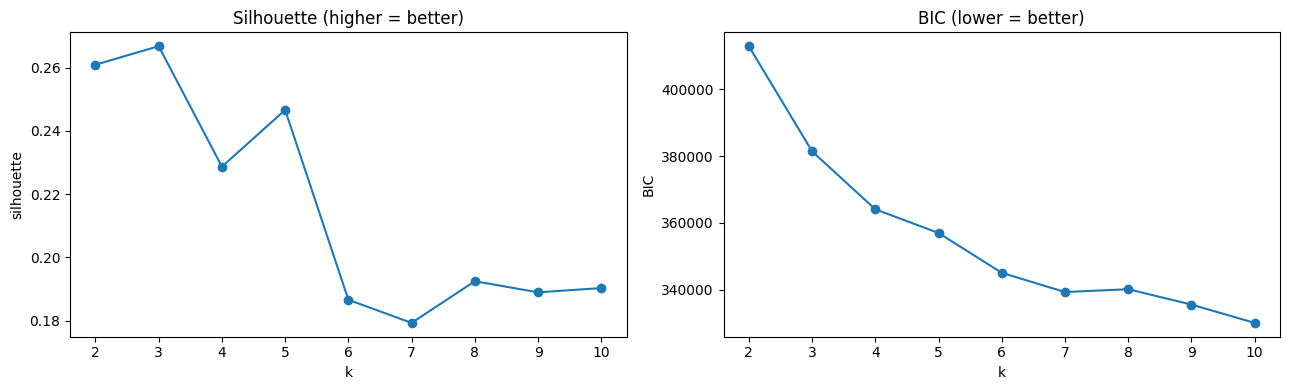

best k by silhouette: 3
best k by BIC:        10


In [5]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

K_RANGE = range(2, 11)
sil, bic = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xr)
    sil.append(silhouette_score(Xr, km.labels_, sample_size=5000, random_state=42))
    gm = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(Xr)
    bic.append(gm.bic(Xr))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(list(K_RANGE), sil, 'o-'); a1.set_title('Silhouette (higher = better)')
a1.set_xlabel('k'); a1.set_ylabel('silhouette')
a2.plot(list(K_RANGE), bic, 'o-'); a2.set_title('BIC (lower = better)')
a2.set_xlabel('k'); a2.set_ylabel('BIC')
plt.tight_layout(); plt.show()

print("best k by silhouette:", list(K_RANGE)[int(np.argmax(sil))])
print("best k by BIC:       ", list(K_RANGE)[int(np.argmin(bic))])

In [28]:
K = 3

km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xr)
labels = km.labels_
print("cluster sizes:")
for c in range(K):
    print(f"  cluster {c}: {(labels==c).sum()} points ({100*(labels==c).mean():.1f}%)")

cluster sizes:
  cluster 0: 1373 points (18.8%)
  cluster 1: 3843 points (52.7%)
  cluster 2: 2070 points (28.4%)


/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


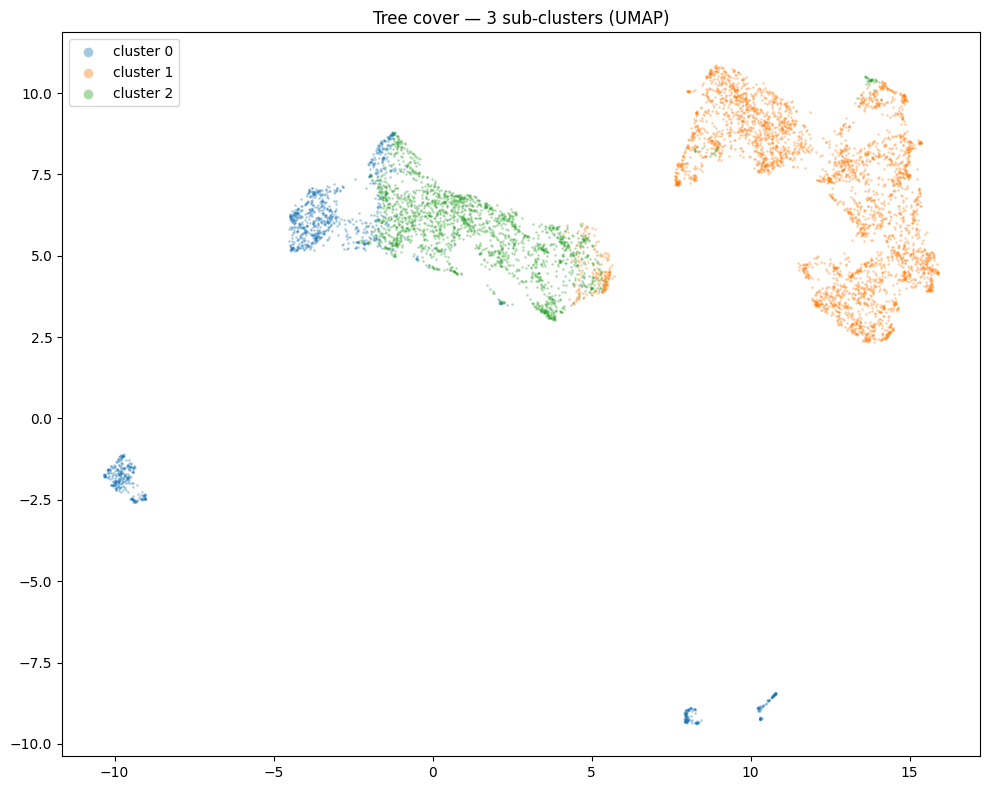

In [29]:
import umap
emb2 = umap.UMAP(n_components=2, random_state=42, init='random').fit_transform(Xr)

fig, ax = plt.subplots(figsize=(10, 8))
for c in range(K):
    m = labels == c
    ax.scatter(emb2[m,0], emb2[m,1], s=3, alpha=0.4, linewidths=0, label=f'cluster {c}')
ax.set_title(f'{TARGET_CLASS} — {K} sub-clusters (UMAP)')
ax.legend(markerscale=4)
plt.tight_layout(); plt.show()

In [30]:
from sklearn.metrics import adjusted_rand_score

# refit on bootstrap subsamples; high ARI across runs = stable clusters
base = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(Xr)
aris = []
for seed in range(1, 6):
    idx = np.random.RandomState(seed).choice(len(Xr), int(0.8*len(Xr)), replace=False)
    sub = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(Xr[idx])
    aris.append(adjusted_rand_score(base[idx], sub))
print(f"stability (mean ARI over 5 bootstraps): {np.mean(aris):.3f}  (>0.7 = stable)")

stability (mean ARI over 5 bootstraps): 0.978  (>0.7 = stable)


In [31]:
import duckdb
import numpy as np

RAW_GLOB = '../data/raw/**/*.parquet'
EMB_COLS = [f'A{i:02d}' for i in range(64)]
TARGET_CLASS = 'Tree cover'
MAX_POINTS = 20000

emb_sel = ", ".join(EMB_COLS)
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
df = con.execute(f"""
    SELECT {emb_sel}, lat, lon, homogeneity,
           regexp_extract(filename, 'raw/[^/]+/([^/]+)/', 1) AS country
    FROM read_parquet('{RAW_GLOB}', filename=true)
    WHERE label_name = '{TARGET_CLASS}'
    USING SAMPLE {MAX_POINTS} ROWS
""").df()
con.close()

X = df[EMB_COLS].to_numpy(dtype='float64')
print(f"{TARGET_CLASS}: {len(df)} points")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tree cover: 7247 points


In [32]:
X = df[EMB_COLS].to_numpy(dtype='float64')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

Xs = StandardScaler().fit_transform(X)
Xr = PCA(n_components=0.90, random_state=42).fit_transform(Xs)

K = 3
labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xr)

df['cluster'] = labels
print((len(labels), len(df)))

(7247, 7247)


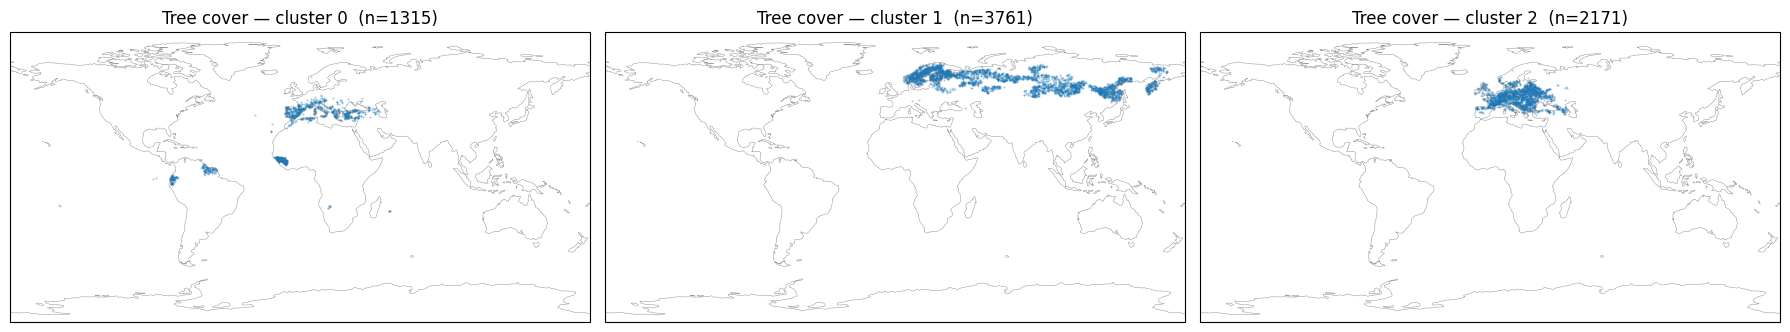

In [33]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, K, figsize=(6*K, 5),
                         subplot_kw={'projection': ccrs.PlateCarree()})

if K == 1: axes = [axes]
for c, ax in enumerate(axes):
    ax.set_global()
    ax.coastlines(linewidth=0.3, color='gray')
    sub = df[df['cluster'] == c]
    ax.scatter(sub['lon'], sub['lat'], s=2, alpha=0.4, linewidths=0,
               transform=ccrs.PlateCarree())
    ax.set_title(f'{TARGET_CLASS} — cluster {c}  (n={len(sub)})')
plt.tight_layout(); plt.show()

In [34]:
import pandas as pd

profile = pd.DataFrame({
    'size':        df.groupby('cluster').size(),
    'mean_lat':    df.groupby('cluster')['lat'].mean(),
    'mean_lon':    df.groupby('cluster')['lon'].mean(),
    'mean_homog':  df.groupby('cluster')['homogeneity'].mean(),
})
print(profile.round(3))

# dominant countries per cluster — another interpretation hook
for c in range(K):
    top = df[df['cluster']==c]['country'].value_counts().head(5)
    print(f"\ncluster {c} top countries:\n{top.to_string()}")

         size  mean_lat  mean_lon  mean_homog
cluster                                      
0        1315    27.626    -5.553       0.913
1        3761    59.778    74.689       0.924
2        2171    49.491    17.494       0.919

cluster 0 top countries:
country
gn    252
es    213
tr    160
ec     98
it     83

cluster 1 top countries:
country
ru    2700
se     388
fi     376
no     226
by      25

cluster 2 top countries:
country
fr    274
de    252
pl    204
ua    178
by    153


In [35]:
# print representative coordinates per cluster to inspect in a basemap / Google Earth / EE
for c in range(K):
    sub = df[df['cluster']==c].sample(min(5, (df['cluster']==c).sum()), random_state=42)
    print(f"\ncluster {c} sample locations (lat, lon) — inspect these:")
    for _, r in sub.iterrows():
        print(f"  {r['lat']:.4f}, {r['lon']:.4f}  ({r['country']})  "
              f"https://www.google.com/maps/@{r['lat']},{r['lon']},2000m/data=!3m1!1e3")


cluster 0 sample locations (lat, lon) — inspect these:
  38.9151, -7.1022  (pt)  https://www.google.com/maps/@38.915101715063265,-7.102224940455615,2000m/data=!3m1!1e3
  11.9889, -12.6363  (gn)  https://www.google.com/maps/@11.988866035280422,-12.63634203171028,2000m/data=!3m1!1e3
  41.4267, 1.5283  (es)  https://www.google.com/maps/@41.42671091635018,1.5283248831669602,2000m/data=!3m1!1e3
  37.8739, -4.8772  (es)  https://www.google.com/maps/@37.873877325416984,-4.877241188703183,2000m/data=!3m1!1e3
  37.1826, 21.7891  (gr)  https://www.google.com/maps/@37.18264068874221,21.78906887023283,2000m/data=!3m1!1e3

cluster 1 sample locations (lat, lon) — inspect these:
  54.3475, 111.5040  (ru)  https://www.google.com/maps/@54.347540211190754,111.50399722268166,2000m/data=!3m1!1e3
  58.0238, 25.1817  (lv)  https://www.google.com/maps/@58.02382975601253,25.181705922667426,2000m/data=!3m1!1e3
  63.5688, 107.5231  (ru)  https://www.google.com/maps/@63.568769665525906,107.52312214514755,2000m/